# Week12 예습과제 — 7장 트랜스포머
- datasets: 허깅 페이스에서 Multi30k 데이터를 불러오기 위해 설치 (torchtext 대체)
- spaCy 독일어·영어 토크나이저 모델 다운로드

In [1]:
# [수정] torchtext 대신 허깅 페이스 datasets 사용
!pip install -q datasets
!python -m spacy download de_core_news_sm -q
!python -m spacy download en_core_web_sm -q

import torch
print("GPU 사용 가능:", torch.cuda.is_available())

✔ Download and installation successful
You can now load the package via spacy.load('de_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
GPU 사용 가능: True


## 예제 7.1 위치 인코딩
- PE(pos, 2i) = sin(pos / 10000^(2i/d_model)), PE(pos, 2i+1) = cos(pos / 10000^(2i/d_model))
- 짝수 칸은 sin, 홀수 칸은 cos → 위치마다 서로 다른 주기적인 벡터를 임베딩에 더함
- register_buffer: 학습되지 않는 값으로 등록 (매개변수 갱신 X)
- pe 텐서 차원: [max_len, 1, d_model] = [50, 1, 128]

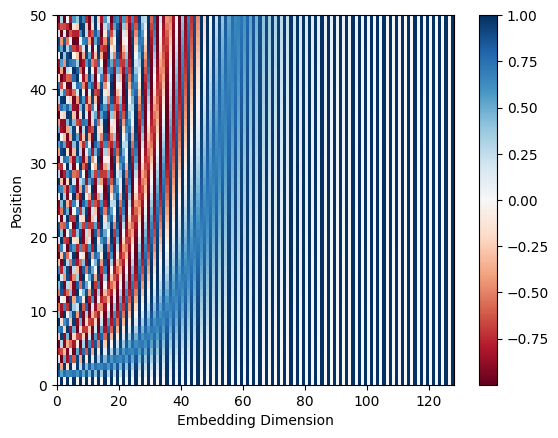

In [2]:
import math
import torch
from torch import nn
from matplotlib import pyplot as plt


class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)

        position = torch.arange(max_len).unsqueeze(1)  # 위치 번호 pos: [max_len, 1]
        div_term = torch.exp(
            torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model)
        )  # 1 / 10000^(2i/d_model)

        pe = torch.zeros(max_len, 1, d_model)
        pe[:, 0, 0::2] = torch.sin(position * div_term)  # 짝수 칸: sin
        pe[:, 0, 1::2] = torch.cos(position * div_term)  # 홀수 칸: cos
        self.register_buffer("pe", pe)

    def forward(self, x):
        x = x + self.pe[: x.size(0)]  # 입력 임베딩 + 위치 인코딩
        return self.dropout(x)


encoding = PositionalEncoding(d_model=128, max_len=50)

plt.pcolormesh(encoding.pe.numpy().squeeze(), cmap="RdBu")
plt.xlabel("Embedding Dimension")
plt.xlim((0, 128))
plt.ylabel("Position")
plt.colorbar()
plt.show()

## 예제 7.2 데이터세트 다운로드 및 전처리
- Multi30k: 영어-독일어 병렬 말뭉치 (약 30,000개)
- 소스 = 독일어(de), 타깃 = 영어(en)
- 특수 토큰: <unk>=0, <pad>=1, <bos>=2, <eos>=3
- token_transform: 언어별 spaCy 토크나이저 / vocab_transform: 토큰 → 인덱스 어휘 사전
- [수정] torchtext가 최신 코랩에서 동작하지 않아, 같은 이름·같은 사용법의 대체 함수를 먼저 정의함

In [3]:
# [수정] torchtext 대체 코드: 아래 교재 코드가 그대로 동작하도록 같은 이름으로 정의
import spacy
import importlib
from collections import Counter
from datasets import load_dataset

importlib.invalidate_caches()  # 방금 설치한 spaCy 모델을 바로 인식하도록

# --- get_tokenizer 대체 ---
def get_tokenizer(tokenizer, language):
    nlp = spacy.load(language)
    def _tokenize(text):
        return [token.text for token in nlp.tokenizer(text)]
    return _tokenize

# --- build_vocab_from_iterator 대체 ---
class Vocab:
    def __init__(self, itos):
        self.itos = itos                                   # 인덱스 → 토큰
        self.stoi = {tok: i for i, tok in enumerate(itos)} # 토큰 → 인덱스
        self.default_index = None

    def __len__(self):
        return len(self.itos)

    def __getitem__(self, token):
        if token in self.stoi:
            return self.stoi[token]
        return self.default_index

    def __call__(self, tokens):                            # 토큰 리스트 → 인덱스 리스트
        return [self[token] for token in tokens]

    def set_default_index(self, index):                    # 사전에 없는 토큰의 기본 인덱스
        self.default_index = index

    def lookup_tokens(self, indices):                      # 인덱스 리스트 → 토큰 리스트
        return [self.itos[i] for i in indices]

    def __repr__(self):
        return "Vocab()"

def build_vocab_from_iterator(iterator, min_freq=1, specials=None, special_first=True):
    counter = Counter()
    for tokens in iterator:
        counter.update(tokens)
    specials = specials or []
    words = [
        tok for tok, freq in sorted(counter.items(), key=lambda x: (-x[1], x[0]))
        if freq >= min_freq and tok not in specials
    ]
    itos = specials + words if special_first else words + specials
    return Vocab(itos)

# --- Multi30k 대체 (허깅 페이스 bentrevett/multi30k) ---
_multi30k = load_dataset("bentrevett/multi30k")

def Multi30k(split="train", language_pair=("de", "en")):
    hf_split = {"train": "train", "valid": "validation", "test": "test"}[split]
    return [(ex[language_pair[0]], ex[language_pair[1]]) for ex in _multi30k[hf_split]]

print({k: len(v) for k, v in _multi30k.items()})

README.md:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

train.jsonl:   0%|          | 0.00/4.60M [00:00<?, ?B/s]

val.jsonl:   0%|          | 0.00/164k [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/156k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/29000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1014 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

{'train': 29000, 'validation': 1014, 'test': 1000}


In [4]:
# [수정] torchtext import 3줄은 위 대체 함수로 바꿈
# from torchtext.datasets import Multi30k
# from torchtext.data.utils import get_tokenizer
# from torchtext.vocab import build_vocab_from_iterator


def generate_tokens(text_iter, language):
    language_index = {SRC_LANGUAGE: 0, TGT_LANGUAGE: 1}

    for text in text_iter:
        yield token_transform[language](text[language_index[language]])


SRC_LANGUAGE = "de"
TGT_LANGUAGE = "en"
UNK_IDX, PAD_IDX, BOS_IDX, EOS_IDX = 0, 1, 2, 3
special_symbols = ["<unk>", "<pad>", "<bos>", "<eos>"]

token_transform = {
    SRC_LANGUAGE: get_tokenizer("spacy", language="de_core_news_sm"),
    TGT_LANGUAGE: get_tokenizer("spacy", language="en_core_web_sm"),
}
print("Token Transform:")
print(token_transform)

vocab_transform = {}
for language in [SRC_LANGUAGE, TGT_LANGUAGE]:
    train_iter = Multi30k(split="train", language_pair=(SRC_LANGUAGE, TGT_LANGUAGE))
    vocab_transform[language] = build_vocab_from_iterator(
        generate_tokens(train_iter, language),
        min_freq=1,
        specials=special_symbols,
        special_first=True,
    )

for language in [SRC_LANGUAGE, TGT_LANGUAGE]:
    vocab_transform[language].set_default_index(UNK_IDX)

print("Vocab Transform:")
print(vocab_transform)

Token Transform:
{'de': <function get_tokenizer.<locals>._tokenize at 0x7d745c39e520>, 'en': <function get_tokenizer.<locals>._tokenize at 0x7d745c249440>}
Vocab Transform:
{'de': Vocab(), 'en': Vocab()}


## 예제 7.3 트랜스포머 모델 구성
- PositionalEncoding: 예제 7.1과 동일
- TokenEmbedding: 토큰 번호 → 임베딩, √emb_size를 곱해 크기 보정
- Seq2SeqTransformer: 소스/타깃 토큰 임베딩 + 위치 인코딩 + nn.Transformer + generator(어휘 사전 로짓)
- encode: 인코더만 / decode: 디코더만 (번역 추론 시 사용)

In [5]:
import math
import torch
from torch import nn


class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)

        position = torch.arange(max_len).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model)
        )

        pe = torch.zeros(max_len, 1, d_model)
        pe[:, 0, 0::2] = torch.sin(position * div_term)
        pe[:, 0, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe)

    def forward(self, x):
        x = x + self.pe[: x.size(0)]
        return self.dropout(x)


class TokenEmbedding(nn.Module):
    def __init__(self, vocab_size, emb_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_size)
        self.emb_size = emb_size

    def forward(self, tokens):
        return self.embedding(tokens.long()) * math.sqrt(self.emb_size)


class Seq2SeqTransformer(nn.Module):
    def __init__(
        self,
        num_encoder_layers,
        num_decoder_layers,
        emb_size,
        max_len,
        nhead,
        src_vocab_size,
        tgt_vocab_size,
        dim_feedforward,
        dropout=0.1,
    ):
        super().__init__()
        self.src_tok_emb = TokenEmbedding(src_vocab_size, emb_size)
        self.tgt_tok_emb = TokenEmbedding(tgt_vocab_size, emb_size)
        self.positional_encoding = PositionalEncoding(
            d_model=emb_size, max_len=max_len, dropout=dropout
        )
        self.transformer = nn.Transformer(
            d_model=emb_size,
            nhead=nhead,
            num_encoder_layers=num_encoder_layers,
            num_decoder_layers=num_decoder_layers,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
        )
        self.generator = nn.Linear(emb_size, tgt_vocab_size)

    def forward(
        self,
        src,
        trg,
        src_mask,
        tgt_mask,
        src_padding_mask,
        tgt_padding_mask,
        memory_key_padding_mask,
    ):
        src_emb = self.positional_encoding(self.src_tok_emb(src))
        tgt_emb = self.positional_encoding(self.tgt_tok_emb(trg))
        outs = self.transformer(
            src=src_emb,
            tgt=tgt_emb,
            src_mask=src_mask,
            tgt_mask=tgt_mask,
            memory_mask=None,
            src_key_padding_mask=src_padding_mask,
            tgt_key_padding_mask=tgt_padding_mask,
            memory_key_padding_mask=memory_key_padding_mask
        )
        return self.generator(outs)

    def encode(self, src, src_mask):
        return self.transformer.encoder(
            self.positional_encoding(self.src_tok_emb(src)), src_mask
        )

    def decode(self, tgt, memory, tgt_mask):
        return self.transformer.decoder(
            self.positional_encoding(self.tgt_tok_emb(tgt)), memory, tgt_mask
        )

## 예제 7.4 트랜스포머 모델 구조
- 인코더 3층, 디코더 3층, 임베딩 512, 헤드 8, 순방향 신경망 512
- 손실 함수: CrossEntropyLoss(ignore_index=PAD_IDX) → 패딩 토큰은 손실 계산 X
- named_children()을 4번 겹쳐 모듈 구조를 트리 모양으로 출력

In [6]:
from torch import optim

BATCH_SIZE = 128
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

model = Seq2SeqTransformer(
    num_encoder_layers=3,
    num_decoder_layers=3,
    emb_size=512,
    max_len=512,
    nhead=8,
    src_vocab_size=len(vocab_transform[SRC_LANGUAGE]),
    tgt_vocab_size=len(vocab_transform[TGT_LANGUAGE]),
    dim_feedforward=512,
).to(DEVICE)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX).to(DEVICE)
optimizer = optim.Adam(model.parameters())

for main_name, main_module in model.named_children():
    print(main_name)
    for sub_name, sub_module in main_module.named_children():
        print("└", sub_name)
        for ssub_name, ssub_module in sub_module.named_children():
            print("│  └", ssub_name)
            for sssub_name, sssub_module in ssub_module.named_children():
                print("│  │  └", sssub_name)

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:145: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.encoder = TransformerEncoder(


src_tok_emb
└ embedding
tgt_tok_emb
└ embedding
positional_encoding
└ dropout
transformer
└ encoder
│  └ layers
│  │  └ 0
│  │  └ 1
│  │  └ 2
│  └ norm
└ decoder
│  └ layers
│  │  └ 0
│  │  └ 1
│  │  └ 2
│  └ norm
generator


## 예제 7.5 배치 데이터 생성
- sequential_transforms: 전처리 함수들을 차례대로 적용 (토큰화 → 인덱스화 → BOS/EOS 추가)
- collator: 줄바꿈 제거 후 전처리, pad_sequence로 PAD(1) 채우기
- 출력 배치 모양: [시퀀스 길이, 배치 크기] → 교재 source [35, 128], target [30, 128]
- 첫 줄은 전부 2(BOS), 마지막 줄들은 1(PAD)

In [7]:
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pad_sequence


def sequential_transforms(*transforms):
    def func(txt_input):
        for transform in transforms:
            txt_input = transform(txt_input)
        return txt_input
    return func


def input_transform(token_ids):
    return torch.cat(
        (torch.tensor([BOS_IDX]), torch.tensor(token_ids), torch.tensor([EOS_IDX]))
    )


def collator(batch):
    src_batch, tgt_batch = [], []
    for src_sample, tgt_sample in batch:
        src_batch.append(text_transform[SRC_LANGUAGE](src_sample.rstrip("\n")))
        tgt_batch.append(text_transform[TGT_LANGUAGE](tgt_sample.rstrip("\n")))

    src_batch = pad_sequence(src_batch, padding_value=PAD_IDX)
    tgt_batch = pad_sequence(tgt_batch, padding_value=PAD_IDX)
    return src_batch, tgt_batch


text_transform = {}
for language in [SRC_LANGUAGE, TGT_LANGUAGE]:
    text_transform[language] = sequential_transforms(
        token_transform[language], vocab_transform[language], input_transform
    )

data_iter = Multi30k(split="valid", language_pair=(SRC_LANGUAGE, TGT_LANGUAGE))
dataloader = DataLoader(data_iter, batch_size=BATCH_SIZE, collate_fn=collator)
source_tensor, target_tensor = next(iter(dataloader))

print("(source, target):")
print(next(iter(data_iter)))

print("source_batch:", source_tensor.shape)
print(source_tensor)

print("target_batch:", target_tensor.shape)
print(target_tensor)

(source, target):
('Eine Gruppe von Männern lädt Baumwolle auf einen Lastwagen', 'A group of men are loading cotton onto a truck')
source_batch: torch.Size([35, 128])
tensor([[   2,    2,    2,  ...,    2,    2,    2],
        [  14,    5,    5,  ...,    5,   21,    5],
        [  38,   12,   35,  ...,   12, 1750,   69],
        ...,
        [   1,    1,    1,  ...,    1,    1,    1],
        [   1,    1,    1,  ...,    1,    1,    1],
        [   1,    1,    1,  ...,    1,    1,    1]])
target_batch: torch.Size([30, 128])
tensor([[   2,    2,    2,  ...,    2,    2,    2],
        [   6,    6,    6,  ...,  250,   19,    6],
        [  39,   12,   35,  ...,   12, 3254,   61],
        ...,
        [   1,    1,    1,  ...,    1,    1,    1],
        [   1,    1,    1,  ...,    1,    1,    1],
        [   1,    1,    1,  ...,    1,    1,    1]])


## 예제 7.6 어텐션 마스크 생성
- generate_square_subsequent_mask: triu → transpose → 0은 -inf, 1은 0.0 (미래 토큰 가리기)
- src_mask: 전부 False → 소스는 모든 토큰 참조
- padding_mask: PAD 위치 True → 어텐션에서 무시, [배치, 길이]로 전치
- target_input = [:-1], target_out = [1:] → 한 칸 시프트해 다음 토큰 예측
- 교재 출력: source_mask [35, 35], target_mask [29, 29], source_padding_mask [128, 35], target_padding_mask [128, 29]

In [8]:
def generate_square_subsequent_mask(s):
    mask = (torch.triu(torch.ones((s, s), device=DEVICE)) == 1).transpose(0, 1)
    mask = (
        mask.float()
        .masked_fill(mask == 0, float("-inf"))
        .masked_fill(mask == 1, float(0.0))
    )
    return mask


def create_mask(src, tgt):
    src_seq_len = src.shape[0]
    tgt_seq_len = tgt.shape[0]

    tgt_mask = generate_square_subsequent_mask(tgt_seq_len)
    src_mask = torch.zeros((src_seq_len, src_seq_len), device=DEVICE).type(torch.bool)

    src_padding_mask = (src == PAD_IDX).transpose(0, 1)
    tgt_padding_mask = (tgt == PAD_IDX).transpose(0, 1)
    return src_mask, tgt_mask, src_padding_mask, tgt_padding_mask


target_input = target_tensor[:-1, :]
target_out = target_tensor[1:, :]

source_mask, target_mask, source_padding_mask, target_padding_mask = create_mask(
    source_tensor, target_input
)

print("source_mask:", source_mask.shape)
print(source_mask)
print("target_mask:", target_mask.shape)
print(target_mask)
print("source_padding_mask:", source_padding_mask.shape)
print(source_padding_mask)
print("target_padding_mask:", target_padding_mask.shape)
print(target_padding_mask)

source_mask: torch.Size([35, 35])
tensor([[False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False],
        ...,
        [False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False]], device='cuda:0')
target_mask: torch.Size([29, 29])
tensor([[0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf,
         -inf, -inf, -inf, -inf, -inf],
        [0., 0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf,
         -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf,
         -inf, -inf, -inf,

## 예제 7.7 모델 학습 및 평가
- run: split이 "train"이면 학습(역전파 O), "valid"면 평가
- 손실 계산 시 logits [길이, 배치, 어휘] → [길이×배치, 어휘], 정답 → [길이×배치]로 펼침
- memory_key_padding_mask = src_padding_mask (디코더가 인코더 출력을 볼 때 소스 PAD 무시)

In [9]:
def run(model, optimizer, criterion, split):
    model.train() if split == "train" else model.eval()
    data_iter = Multi30k(split=split, language_pair=(SRC_LANGUAGE, TGT_LANGUAGE))
    dataloader = DataLoader(data_iter, batch_size=BATCH_SIZE, collate_fn=collator)

    losses = 0
    for source_batch, target_batch in dataloader:
        source_batch = source_batch.to(DEVICE)
        target_batch = target_batch.to(DEVICE)

        target_input = target_batch[:-1, :]
        target_output = target_batch[1:, :]

        src_mask, tgt_mask, src_padding_mask, tgt_padding_mask = create_mask(
            source_batch, target_input
        )

        logits = model(
            src=source_batch,
            trg=target_input,
            src_mask=src_mask,
            tgt_mask=tgt_mask,
            src_padding_mask=src_padding_mask,
            tgt_padding_mask=tgt_padding_mask,
            memory_key_padding_mask=src_padding_mask,
        )

        optimizer.zero_grad()
        loss = criterion(logits.reshape(-1, logits.shape[-1]), target_output.reshape(-1))
        if split == "train":
            loss.backward()
            optimizer.step()
        losses += loss.item()

    return losses / len(list(dataloader))


for epoch in range(5):
    train_loss = run(model, optimizer, criterion, "train")
    val_loss = run(model, optimizer, criterion, "valid")
    print(f"Epoch: {epoch+1}, Train loss: {train_loss:.3f}, Val loss: {val_loss:.3f}")

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/activation.py:1337: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(


Epoch: 1, Train loss: 4.524, Val loss: 3.840
Epoch: 2, Train loss: 3.627, Val loss: 3.560
Epoch: 3, Train loss: 3.359, Val loss: 3.476
Epoch: 4, Train loss: 3.203, Val loss: 3.438
Epoch: 5, Train loss: 3.087, Val loss: 3.443


## 예제 7.8 트랜스포머 모델 번역 결과
- 그리디 디코딩: 매 단계 확률이 가장 높은 단어 선택, EOS 또는 max_len(소스 토큰 수 + 5)까지 반복
- memory = 인코더 출력 / ys = [BOS]에서 시작해 단어를 하나씩 붙임
- lookup_tokens로 인덱스 → 단어, [1:-1]로 <bos>, <eos> 제거
- 'Iglu'(이글루)는 학습하지 않은 OOV 단어 → 'Gebäude'(건물)와 같은 번역이 나옴
- 학습 결과에 따라 번역 문장은 교재와 조금 다를 수 있음

In [10]:
def greedy_decode(model, source_tensor, source_mask, max_len, start_symbol):
    source_tensor = source_tensor.to(DEVICE)
    source_mask = source_mask.to(DEVICE)

    memory = model.encode(source_tensor, source_mask)
    ys = torch.ones(1, 1).fill_(start_symbol).type(torch.long).to(DEVICE)
    for i in range(max_len - 1):
        memory = memory.to(DEVICE)
        target_mask = generate_square_subsequent_mask(ys.size(0))
        target_mask = target_mask.type(torch.bool).to(DEVICE)

        out = model.decode(ys, memory, target_mask)
        out = out.transpose(0, 1)
        prob = model.generator(out[:, -1])
        _, next_word = torch.max(prob, dim=1)
        next_word = next_word.item()

        ys = torch.cat(
            [ys, torch.ones(1, 1).type_as(source_tensor.data).fill_(next_word)], dim=0
        )
        if next_word == EOS_IDX:
            break
    return ys


def translate(model, source_sentence):
    model.eval()
    source_tensor = text_transform[SRC_LANGUAGE](source_sentence).view(-1, 1)
    num_tokens = source_tensor.shape[0]
    src_mask = (torch.zeros(num_tokens, num_tokens)).type(torch.bool)
    tgt_tokens = greedy_decode(
        model, source_tensor, src_mask, max_len=num_tokens + 5, start_symbol=BOS_IDX
    ).flatten()
    output = vocab_transform[TGT_LANGUAGE].lookup_tokens(list(tgt_tokens.cpu().numpy()))[1:-1]
    return " ".join(output)


output_oov = translate(model, "Eine Gruppe von Menschen steht vor einem Iglu .")
output = translate(model, "Eine Gruppe von Menschen steht vor einem Gebäude .")
print(output_oov)
print(output)

A group of people are standing on a bench in a field .
A group of people are standing on a bench in a field .


## 예제 7.9 문장 생성을 위한 GPT-2 모델의 구조
- 허깅 페이스 transformers의 GPT2LMHeadModel로 사전 학습된 gpt2(디코더 12층) 불러오기
- wte: 단어 토큰 임베딩 / wpe: 단어 위치 임베딩 / drop: 드롭아웃
- h: 디코더 계층 0~11 (ln_1 → attn → ln_2 → mlp) / ln_f: 마지막 정규화
- lm_head: 선형 임베딩 및 언어 모델 (어휘 사전 로짓)
- 48층 모델은 "gpt2-xl"

In [11]:
from transformers import GPT2LMHeadModel

model = GPT2LMHeadModel.from_pretrained(pretrained_model_name_or_path="gpt2")

for main_name, main_module in model.named_children():
    print(main_name)
    for sub_name, sub_module in main_module.named_children():
        print("└", sub_name)
        for ssub_name, ssub_module in sub_module.named_children():
            print("│  └", ssub_name)
            for sssub_name, sssub_module in ssub_module.named_children():
                print("│  │  └", sssub_name)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

transformer
└ wte
└ wpe
└ drop
└ h
│  └ 0
│  │  └ ln_1
│  │  └ attn
│  │  └ ln_2
│  │  └ mlp
│  └ 1
│  │  └ ln_1
│  │  └ attn
│  │  └ ln_2
│  │  └ mlp
│  └ 2
│  │  └ ln_1
│  │  └ attn
│  │  └ ln_2
│  │  └ mlp
│  └ 3
│  │  └ ln_1
│  │  └ attn
│  │  └ ln_2
│  │  └ mlp
│  └ 4
│  │  └ ln_1
│  │  └ attn
│  │  └ ln_2
│  │  └ mlp
│  └ 5
│  │  └ ln_1
│  │  └ attn
│  │  └ ln_2
│  │  └ mlp
│  └ 6
│  │  └ ln_1
│  │  └ attn
│  │  └ ln_2
│  │  └ mlp
│  └ 7
│  │  └ ln_1
│  │  └ attn
│  │  └ ln_2
│  │  └ mlp
│  └ 8
│  │  └ ln_1
│  │  └ attn
│  │  └ ln_2
│  │  └ mlp
│  └ 9
│  │  └ ln_1
│  │  └ attn
│  │  └ ln_2
│  │  └ mlp
│  └ 10
│  │  └ ln_1
│  │  └ attn
│  │  └ ln_2
│  │  └ mlp
│  └ 11
│  │  └ ln_1
│  │  └ attn
│  │  └ ln_2
│  │  └ mlp
└ ln_f
lm_head


## 예제 7.10 GPT-2를 이용한 문장 생성
- pipeline(task="text-generation", model="gpt2") → TextGenerationPipeline 인스턴스
- text_inputs: 입력 문맥 / max_length: 최대 토큰 수 / num_return_sequences: 생성할 문장 수
- pad_token_id: GPT-2엔 패딩 토큰이 없어서 EOS ID로 지정
- 샘플링 방식이라 실행할 때마다 생성 문장이 다름

In [12]:
from transformers import pipeline

generator = pipeline(task="text-generation", model="gpt2")
outputs = generator(
    text_inputs="Machine learning is",
    max_length=20,
    num_return_sequences=3,
    pad_token_id=generator.tokenizer.eos_token_id
)
print(outputs)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'generated_text': 'Machine learning is becoming a big part of the future.\n\nIn the past few years, we'}, {'generated_text': 'Machine learning is just like any other field in biology. In fact, the concept of "learning"'}, {'generated_text': 'Machine learning is the key to making it work. So is building a more efficient, scalable, and'}]


## 예제 7.11 CoLA 데이터세트 불러오기
- CoLA: 문법적으로 올바른 문장(1) / 올바르지 않은 문장(0) 영어 말뭉치 → 이진 분류
- collator: zip(*batch)로 (출처, 레이블, 문장) 분리 → 토큰화(padding="longest", truncation=True, return_tensors="pt")
- input_ids: 토큰 ID / attention_mask: 실제 단어 1, 패딩 0
- GPT-2는 패딩 토큰이 없으므로 pad_token = eos_token
- [수정] torchtext CoLA 대신 CoLA 공식 파일을 직접 내려받는 같은 이름의 대체 함수 사용

In [13]:
# [수정] torchtext.datasets.CoLA 대체: CoLA 공식 파일을 직접 내려받아 같은 형식 (출처, 레이블, 문장)으로 반환
import os
import zipfile
import urllib.request

COLA_URL = "https://nyu-mll.github.io/CoLA/cola_public_1.1.zip"
COLA_FILES = {
    "train": "cola_public/raw/in_domain_train.tsv",
    "dev": "cola_public/raw/in_domain_dev.tsv",
    "test": "cola_public/raw/out_of_domain_dev.tsv",
}

try:
    if not os.path.exists("cola_public"):
        urllib.request.urlretrieve(COLA_URL, "cola_public_1.1.zip")
        with zipfile.ZipFile("cola_public_1.1.zip") as f:
            f.extractall(".")
    USE_OFFICIAL = True
except Exception as e:
    # 공식 파일 다운로드가 안 되면 허깅 페이스 GLUE CoLA로 대체 (개수가 교재와 조금 다름)
    print("공식 파일 다운로드 실패 → 허깅 페이스 GLUE CoLA 사용:", e)
    _glue_cola = load_dataset("nyu-mll/glue", "cola")
    USE_OFFICIAL = False


def CoLA(split="train"):
    if USE_OFFICIAL:
        with open(COLA_FILES[split], encoding="utf-8") as f:
            lines = f.read().splitlines()[1:]  # torchtext와 같이 첫 줄을 건너뜀 → 교재 개수와 일치
        rows = []
        for line in lines:
            parts = line.split("\t")
            rows.append((parts[0], int(parts[1]), parts[3]))  # (출처, 레이블, 문장)
        return rows

    valid = _glue_cola["validation"]
    if split == "train":
        data = _glue_cola["train"]
    elif split == "dev":
        data = valid.select(range(0, 527))
    else:
        data = valid.select(range(527, len(valid)))
    return [("glue", ex["label"], ex["sentence"]) for ex in data]

In [14]:
import torch
# from torchtext.datasets import CoLA  # [수정] 위 대체 함수 사용
from transformers import AutoTokenizer
from torch.utils.data import DataLoader


def collator(batch, tokenizer, device):
    source, labels, texts = zip(*batch)
    tokenized = tokenizer(
        texts,
        padding="longest",
        truncation=True,
        return_tensors="pt"
    )
    input_ids = tokenized["input_ids"].to(device)
    attention_mask = tokenized["attention_mask"].to(device)
    labels = torch.tensor(labels, dtype=torch.long).to(device)
    return input_ids, attention_mask, labels


train_data = list(CoLA(split="train"))
valid_data = list(CoLA(split="dev"))
test_data = list(CoLA(split="test"))

tokenizer = AutoTokenizer.from_pretrained("gpt2")
tokenizer.pad_token = tokenizer.eos_token

epochs = 3
batch_size = 16
device = "cuda" if torch.cuda.is_available() else "cpu"

train_dataloader = DataLoader(
    train_data,
    batch_size=batch_size,
    collate_fn=lambda x: collator(x, tokenizer, device),
    shuffle=True,
)
valid_dataloader = DataLoader(
    valid_data, batch_size=batch_size, collate_fn=lambda x: collator(x, tokenizer, device)
)
test_dataloader = DataLoader(
    test_data, batch_size=batch_size, collate_fn=lambda x: collator(x, tokenizer, device)
)

print("Train Dataset Length :", len(train_data))
print("Valid Dataset Length :", len(valid_data))
print("Test Dataset Length :", len(test_data))

Train Dataset Length : 8550
Valid Dataset Length : 526
Test Dataset Length : 515


## 예제 7.12 GPT-2 모델 설정
- GPT2ForSequenceClassification: GPT-2 몸통 + 분류용 최종 출력 계층
- num_labels=2 (문법 맞음 / 틀림)
- 모델 설정에도 pad_token_id = eos_token_id
- Adam, 학습률 5e-5 (= 0.00005, 사전 학습된 가중치를 조금만 조정)
- 분류 계층(score)은 새로 초기화되므로 "newly initialized" 경고가 뜨는 것이 정상

In [15]:
from torch import optim
from transformers import GPT2ForSequenceClassification

model = GPT2ForSequenceClassification.from_pretrained(
    pretrained_model_name_or_path="gpt2",
    num_labels=2
).to(device)
model.config.pad_token_id = model.config.eos_token_id
optimizer = optim.Adam(model.parameters(), lr=5e-5)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2ForSequenceClassification LOAD REPORT from: gpt2
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


## 예제 7.13 GPT-2 모델 학습 및 검증
- train: labels를 같이 넣으면 모델이 손실을 직접 계산 → outputs.loss
- evaluation: torch.no_grad() + CrossEntropyLoss로 로짓과 레이블에서 손실 직접 계산, calc_accuracy로 정확도
- best_loss = 10000에서 시작 → 검증 손실이 더 작아질 때만 가중치 저장

In [16]:
import os
import numpy as np
from torch import nn

os.makedirs("../models", exist_ok=True)  # [수정] 저장 폴더 생성


def calc_accuracy(preds, labels):
    pred_flat = np.argmax(preds, axis=1).flatten()
    labels_flat = labels.flatten()
    return np.sum(pred_flat == labels_flat) / len(labels_flat)


def train(model, optimizer, dataloader):
    model.train()
    train_loss = 0.0

    for input_ids, attention_mask, labels in dataloader:
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        train_loss += loss.item()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    train_loss = train_loss / len(dataloader)
    return train_loss


def evaluation(model, dataloader):
    with torch.no_grad():
        model.eval()
        criterion = nn.CrossEntropyLoss()
        val_loss, val_accuracy = 0.0, 0.0

        for input_ids, attention_mask, labels in dataloader:
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )
            logits = outputs.logits

            loss = criterion(logits, labels)
            logits = logits.detach().cpu().numpy()
            label_ids = labels.to("cpu").numpy()
            accuracy = calc_accuracy(logits, label_ids)

            val_loss += loss
            val_accuracy += accuracy

    val_loss = val_loss/len(dataloader)
    val_accuracy = val_accuracy/len(dataloader)
    return val_loss, val_accuracy


best_loss = 10000
for epoch in range(epochs):
    train_loss = train(model, optimizer, train_dataloader)
    val_loss, val_accuracy = evaluation(model, valid_dataloader)
    print(f"Epoch {epoch + 1}: Train Loss: {train_loss:.4f} Val Loss: {val_loss:.4f} Val Accuracy {val_accuracy:.4f}")

    if val_loss < best_loss:
        best_loss = val_loss
        torch.save(model.state_dict(), "../models/GPT2ForSequenceClassification.pt")
        print("Saved the model weights")

Epoch 1: Train Loss: 0.6100 Val Loss: 0.5418 Val Accuracy 0.7235
Saved the model weights
Epoch 2: Train Loss: 0.5065 Val Loss: 0.4622 Val Accuracy 0.7787
Saved the model weights
Epoch 3: Train Loss: 0.3616 Val Loss: 0.5271 Val Accuracy 0.7692


## 예제 7.14 모델 평가
- 같은 구조의 모델을 새로 만들고, 저장해 둔 최적 가중치(검증 손실 최저)를 불러와 테스트
- 교재 결과: Test Loss 0.5712, Test Accuracy 0.7431
- CoLA는 올바른 문장이 약 70%인 불균형 데이터 → 정확도만으로 판단하지 않도록 주의

In [17]:
model = GPT2ForSequenceClassification.from_pretrained(
    pretrained_model_name_or_path="gpt2",
    num_labels=2
).to(device)
model.config.pad_token_id = model.config.eos_token_id
model.load_state_dict(torch.load("../models/GPT2ForSequenceClassification.pt"))

test_loss, test_accuracy = evaluation(model, test_dataloader)
print(f"Test Loss : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2ForSequenceClassification LOAD REPORT from: gpt2
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Test Loss : 0.5368
Test Accuracy : 0.7361
